
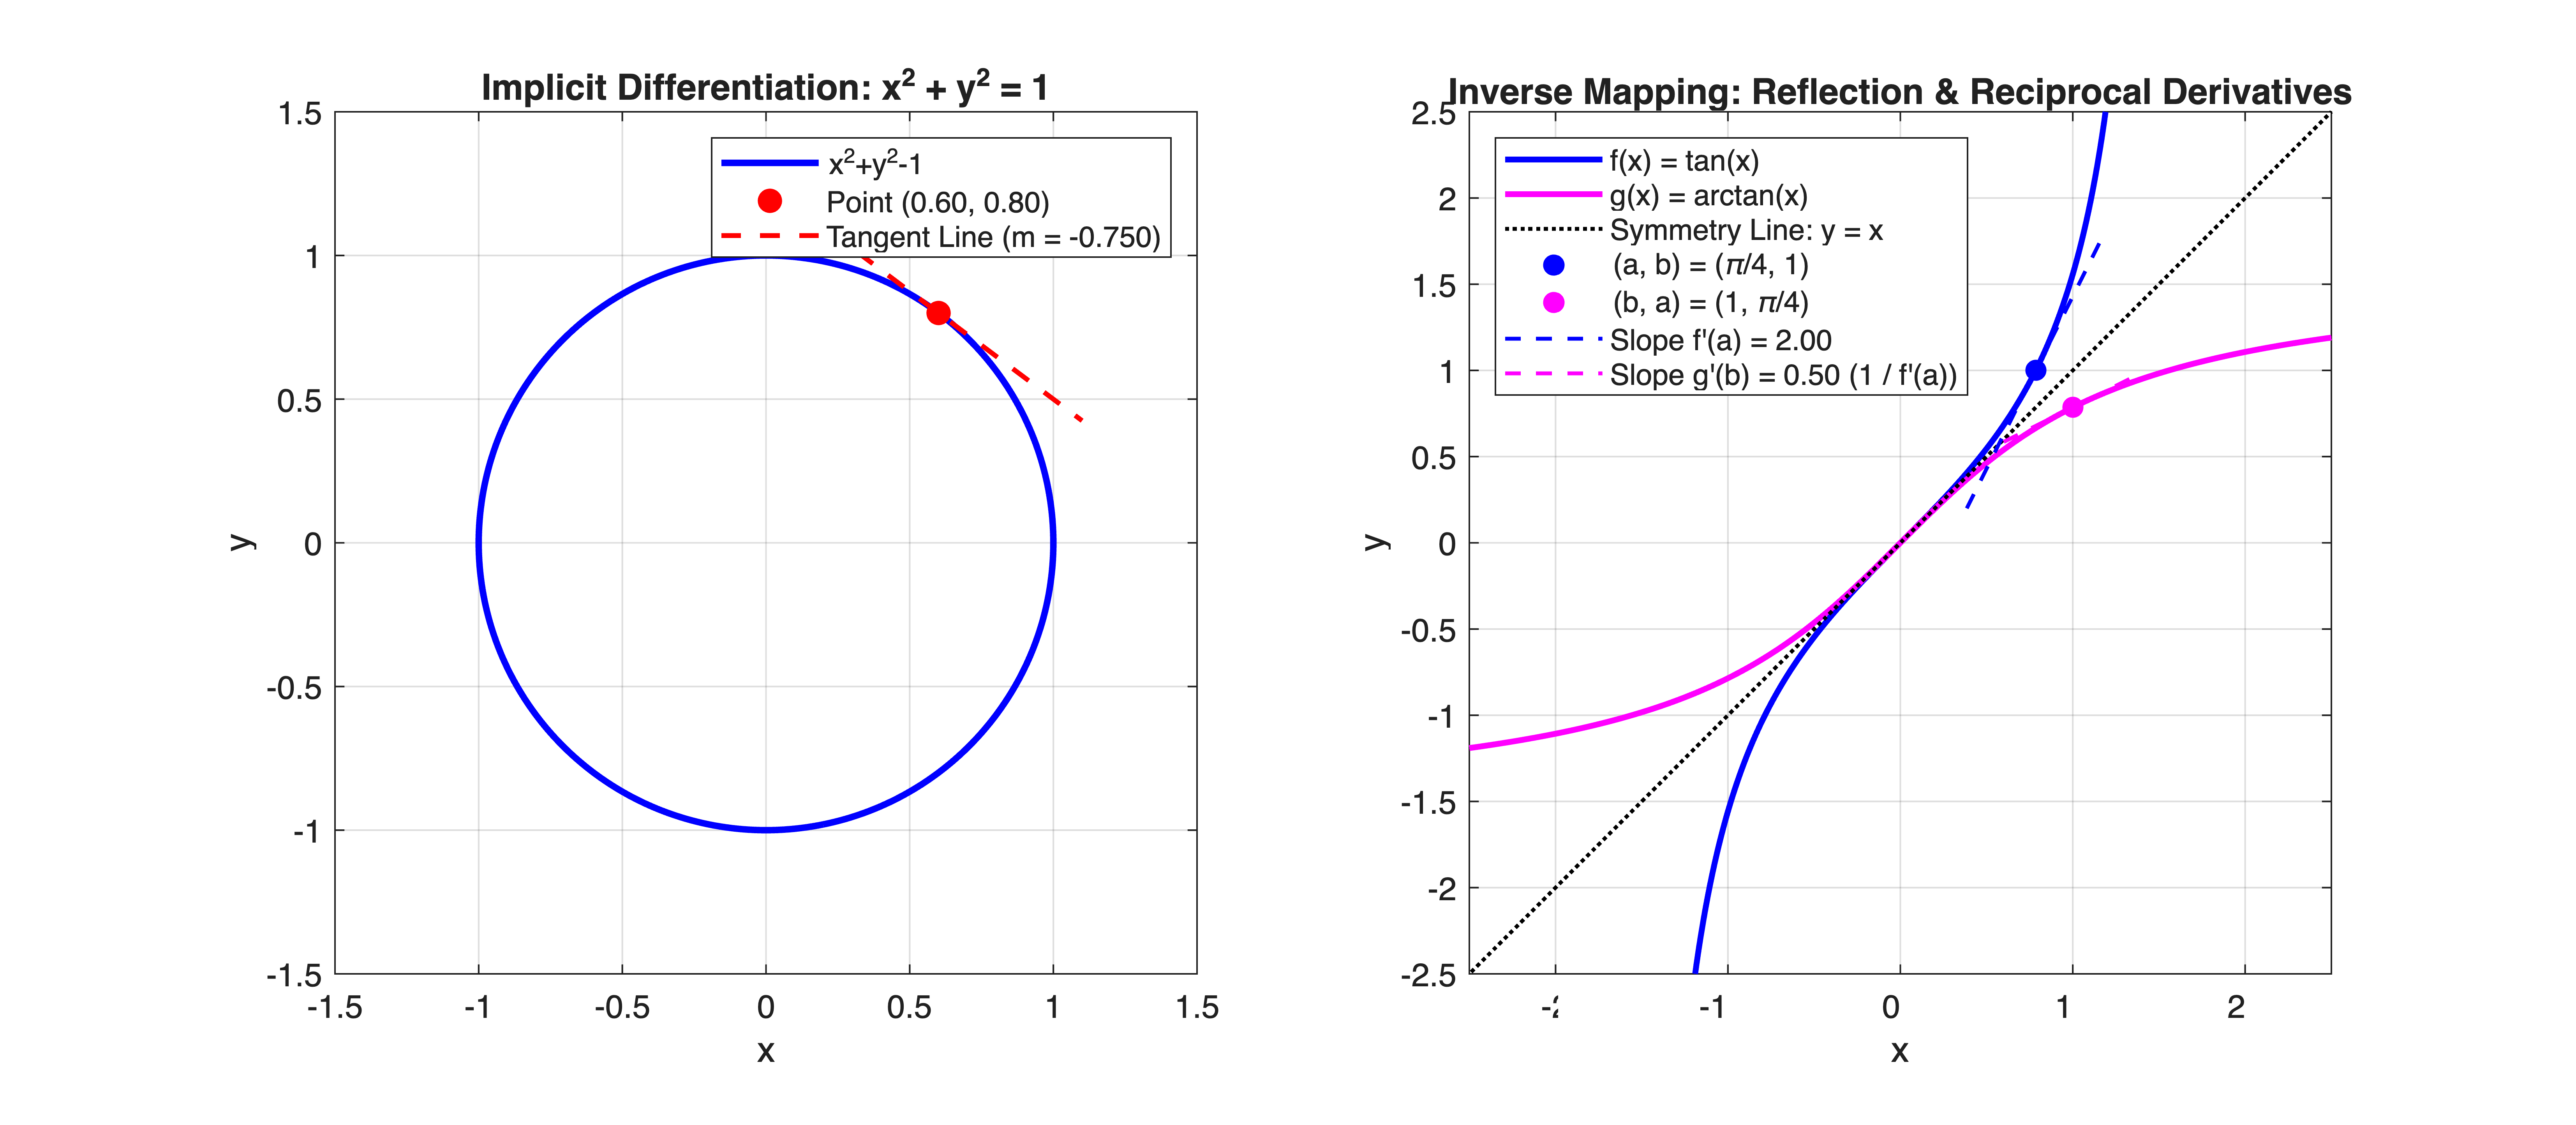

In [1]:
%% MIT 18.01 Lecture 5: Implicit Differentiation and Inverse Functions
% Mathematical Tool Application: Used for resolving differential-algebraic
% equations (DAEs), computing inverse kinematic Jacobians, and deriving
% sensor observation matrices in attitude estimation algorithms.


clear; clc; close all;


%% Part 1: Implicit Differentiation Verification (Circle & Algebraic Curve)
% Case 1: Unit Circle x^2 + y^2 = 1 => dy/dx = -x/y
x0 = 0.6;
y0 = sqrt(1 - x0^2);
slope_circle = -x0 / y0;


% Case 2: Implicit Equation y^3 + x*y^2 + 1 = 0
% dy/dx = -y^2 / (3*y^2 + 2*x*y)
syms x_sym y_sym
F_algebraic = y_sym^3 + x_sym * y_sym^2 + 1;
y_eval = -2.0; % Choose a specific operating y
x_eval = double(solve(subs(F_algebraic, y_sym, y_eval) == 0, x_sym));
slope_algebraic = -(y_eval^2) / (3 * y_eval^2 + 2 * x_eval * y_eval);


figure('Color', 'w', 'Position', [100, 100, 1100, 480]);


subplot(1, 2, 1);
fimplicit(@(x, y) x.^2 + y.^2 - 1, [-1.5, 1.5, -1.5, 1.5], 'b-', 'LineWidth', 2); hold on;
plot(x0, y0, 'ro', 'MarkerSize', 7, 'MarkerFaceColor', 'r', 'DisplayName', sprintf('Point (%.2f, %.2f)', x0, y0));


% Plot tangent line
x_tan_span = linspace(x0 - 0.5, x0 + 0.5, 50);
y_tan_span = y0 + slope_circle * (x_tan_span - x0);
plot(x_tan_span, y_tan_span, 'r--', 'LineWidth', 1.5, ...
    'DisplayName', sprintf('Tangent Line (m = %.3f)', slope_circle));


axis equal; grid on;
xlim([-1.5, 1.5]); ylim([-1.5, 1.5]);
xlabel('x'); ylabel('y');
title('Implicit Differentiation: x^2 + y^2 = 1');
legend('Location', 'northeast');
%% Part 2: Inverse Functions & Reciprocal Slopes (tan vs. arctan)
% Operating point: a = pi/4 => b = tan(pi/4) = 1
a = pi / 4;
b = tan(a);
slope_tan = sec(a)^2;            % d/dx[tan(x)] = 1 + tan^2(x) = 2
slope_arctan = 1 / (1 + b^2);     % d/dy[arctan(y)] = 1 / slope_tan = 0.5


x_span = linspace(-1.3, 1.3, 200);
y_tan_curve = tan(x_span);


y_span = linspace(-3.0, 3.0, 200);
x_arctan_curve = atan(y_span);


subplot(1, 2, 2);
plot(x_span, y_tan_curve, 'b-', 'LineWidth', 1.8, 'DisplayName', 'f(x) = tan(x)'); hold on;
plot(y_span, x_arctan_curve, 'm-', 'LineWidth', 1.8, 'DisplayName', 'g(x) = arctan(x)');
plot([-3, 3], [-3, 3], 'k:', 'LineWidth', 1.2, 'DisplayName', 'Symmetry Line: y = x');


% Mark operating points
plot(a, b, 'bo', 'MarkerFaceColor', 'b', 'DisplayName', sprintf('(a, b) = (\\pi/4, 1)'));
plot(b, a, 'mo', 'MarkerFaceColor', 'm', 'DisplayName', sprintf('(b, a) = (1, \\pi/4)'));


% Tangent on tan(x)
dx = 0.4;
plot([a - dx, a + dx], [b - slope_tan * dx, b + slope_tan * dx], 'b--', 'LineWidth', 1.2, ...
    'DisplayName', sprintf('Slope f''(a) = %.2f', slope_tan));


% Tangent on arctan(x)
plot([b - dx, b + dx], [a - slope_arctan * dx, a + slope_arctan * dx], 'm--', 'LineWidth', 1.2, ...
    'DisplayName', sprintf('Slope g''(b) = %.2f (1 / f''(a))', slope_arctan));


axis equal; grid on;
xlim([-2.5, 2.5]); ylim([-2.5, 2.5]);
xlabel('x'); ylabel('y');
title('Inverse Mapping: Reflection & Reciprocal Derivatives');
legend('Location', 'northwest');